# Healthcare Cost Pattern Discovery & Unusual Billing Detection
Using **K-Means** for customer segmentation and **DBSCAN** for atypical billing anomaly detection.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)


## 1. Load Data
Check dataset shape, missing values, and remove any duplicate rows.


In [2]:
df = pd.read_csv('data/insurance.csv')
print(f'Shape: {df.shape}')
print(f'Null values: {df.isnull().sum().sum()}')

dup_count = df.duplicated().sum()
print(f'Duplicates found: {dup_count}')
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f'Clean records: {len(df)}')

df.head()


Shape: (1338, 7)
Null values: 0
Duplicates found: 1
Clean records: 1337


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Exploratory Data Analysis (EDA)
Check distributions of Age, BMI, and Charges, plus correlation heatmap.


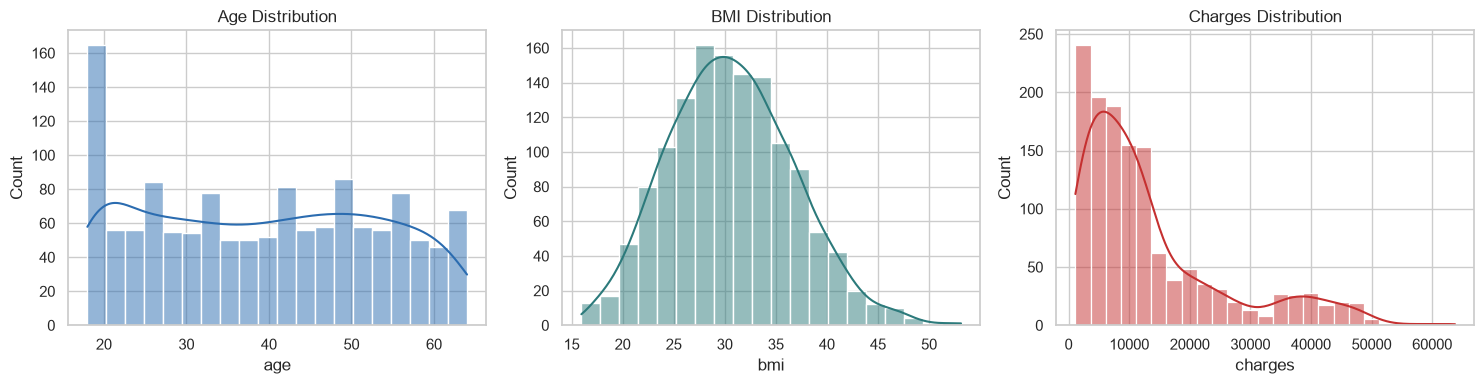

C:\Users\shriy\AppData\Local\Temp\ipykernel_23408\4291916810.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='smoker', y='charges', palette=['#2c7a7b', '#c53030'])


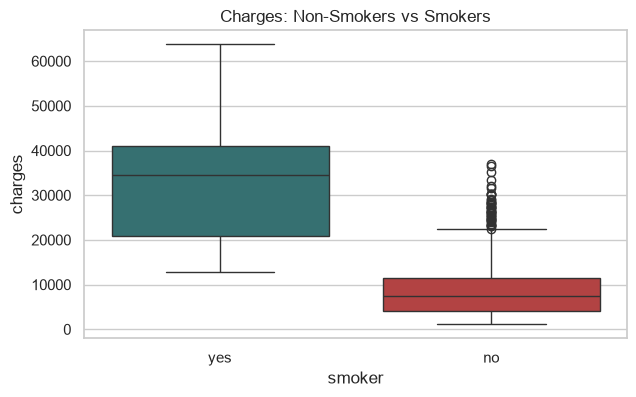

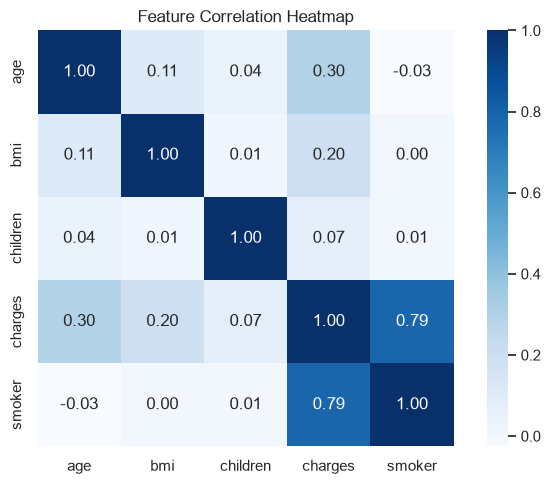

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['age'], kde=True, ax=axes[0], color='#2b6cb0', bins=20)
axes[0].set_title('Age Distribution')

sns.histplot(df['bmi'], kde=True, ax=axes[1], color='#2c7a7b', bins=20)
axes[1].set_title('BMI Distribution')

sns.histplot(df['charges'], kde=True, ax=axes[2], color='#c53030', bins=25)
axes[2].set_title('Charges Distribution')
plt.tight_layout()
plt.show()

# Smoker status vs charges boxplot
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='smoker', y='charges', palette=['#2c7a7b', '#c53030'])
plt.title('Charges: Non-Smokers vs Smokers')
plt.show()

# Correlation Heatmap
plt.figure(figsize=(7, 5))
num_df = df[['age', 'bmi', 'children', 'charges']].copy()
num_df['smoker'] = df['smoker'].map({'yes': 1, 'no': 0})
sns.heatmap(num_df.corr(), annot=True, cmap='Blues', fmt='.2f', square=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


## 3. Preprocessing & Feature Scaling
Encode smoker (0/1) and scale features using `StandardScaler` so `charges` does not overpower distance calculations.


In [4]:
df['smoker_encoded'] = df['smoker'].map({'yes': 1, 'no': 0}).astype(int)
features = ['age', 'bmi', 'smoker_encoded', 'charges']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features].values)
print(f'Scaled feature matrix: {X_scaled.shape}')


Scaled feature matrix: (1337, 4)


## 4. K-Means: Elbow Method & Silhouette Score
Test K = 2 to 8 to choose the optimal number of clusters.


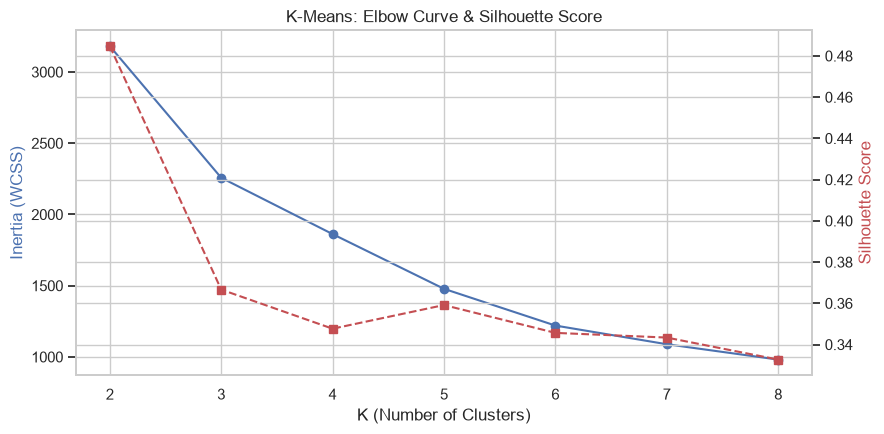

Cluster distribution (K=4):
kmeans_cluster
0    430
1    273
2    390
3    244
Name: count, dtype: int64


In [5]:
k_range = range(2, 9)
inertias = []
sil_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(k_range, inertias, 'bo-', label='Inertia / WCSS')
ax1.set_xlabel('K (Number of Clusters)')
ax1.set_ylabel('Inertia (WCSS)', color='b')

ax2 = ax1.twinx()
ax2.plot(k_range, sil_scores, 'rs--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')

plt.title('K-Means: Elbow Curve & Silhouette Score')
plt.tight_layout()
plt.show()

# Fit optimal K=4 (lowest Davies-Bouldin index)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)
print('Cluster distribution (K=4):')
print(df['kmeans_cluster'].value_counts().sort_index())


## 5. DBSCAN: k-Distance Graph & Outlier Detection
Use an 8-distance graph to pick eps around the knee point, then fit DBSCAN.


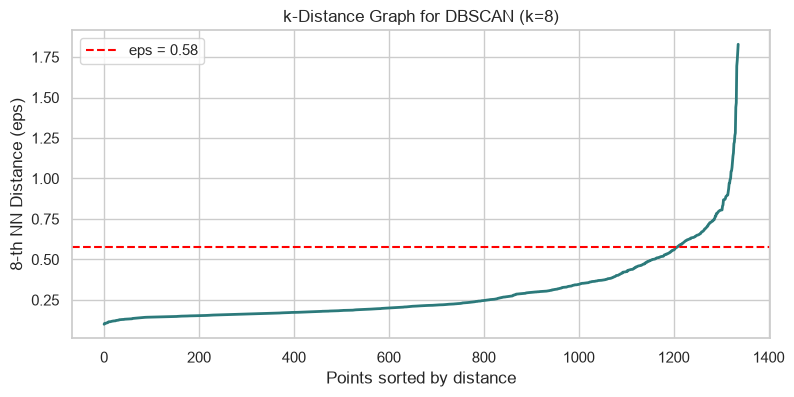

Dense clusters: 5
Atypical noise records: 63 (4.71%)


In [6]:
k_neighbors = 8
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, k_neighbors - 1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances, color='#2c7a7b', lw=2)
plt.axhline(y=0.58, color='red', linestyle='--', label='eps = 0.58')
plt.title('k-Distance Graph for DBSCAN (k=8)')
plt.xlabel('Points sorted by distance')
plt.ylabel('8-th NN Distance (eps)')
plt.legend()
plt.show()

# Fit DBSCAN
eps = 0.58
min_samples = 8
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

n_noise = (df['dbscan_cluster'] == -1).sum()
print(f'Dense clusters: {len(set(df["dbscan_cluster"])) - 1}')
print(f'Atypical noise records: {n_noise} ({n_noise / len(df) * 100:.2f}%)')


## 6. Evaluation: 3 Simple Metrics
We compare K-Means and DBSCAN using 3 standard metrics:
1. **Silhouette Score** (Higher = better separated)
2. **Davies–Bouldin Index** (Lower = better compact clusters)
3. **Outlier / Noise %** (Percentage of unusual records flagged)


In [7]:
km_sil = silhouette_score(X_scaled, df['kmeans_cluster'])
km_db = davies_bouldin_score(X_scaled, df['kmeans_cluster'])

db_mask = df['dbscan_cluster'] != -1
db_sil = silhouette_score(X_scaled[db_mask], df.loc[db_mask, 'dbscan_cluster'])
db_db = davies_bouldin_score(X_scaled[db_mask], df.loc[db_mask, 'dbscan_cluster'])
db_noise = (df['dbscan_cluster'] == -1).sum() / len(df) * 100

metrics_df = pd.DataFrame([
    {
        'Algorithm': 'K-Means (Centroid)',
        'Clusters': 4,
        'Silhouette Score': round(km_sil, 4),
        'Davies-Bouldin Index': round(km_db, 4),
        'Noise / Outlier %': '0.0%'
    },
    {
        'Algorithm': 'DBSCAN (Density)',
        'Clusters': len(set(df['dbscan_cluster'])) - 1,
        'Silhouette Score': round(db_sil, 4),
        'Davies-Bouldin Index': round(db_db, 4),
        'Noise / Outlier %': f'{db_noise:.2f}%'
    }
])
metrics_df


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Noise / Outlier %
0,K-Means (Centroid),4,0.3477,0.9338,0.0%
1,DBSCAN (Density),5,0.0614,1.1254,4.71%


## 7. Cluster Visualizations (No PCA)
Plotting directly on real domain features: Charges vs Age and Charges vs BMI.


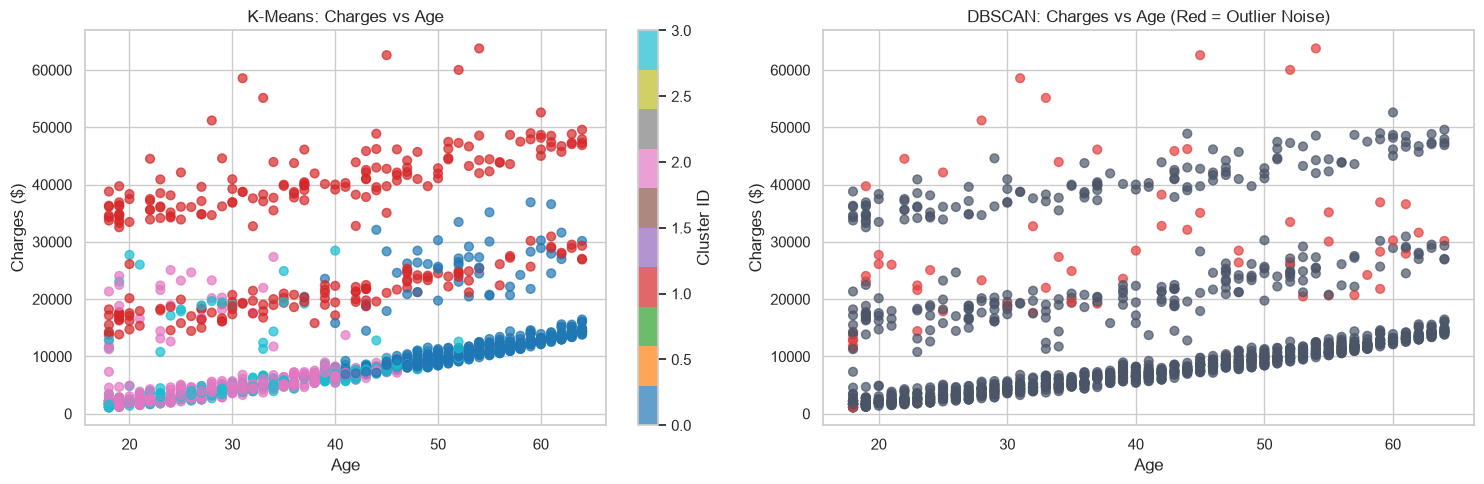

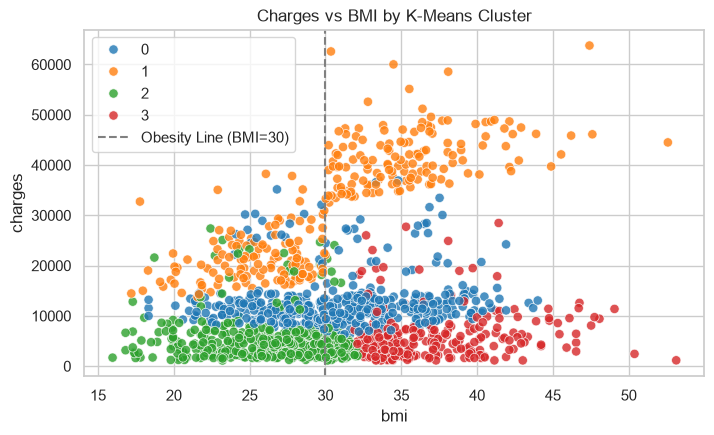

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: K-Means clusters
scatter = axes[0].scatter(df['age'], df['charges'], c=df['kmeans_cluster'], cmap='tab10', alpha=0.7, s=40)
axes[0].set_title('K-Means: Charges vs Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Charges ($)')
plt.colorbar(scatter, ax=axes[0], label='Cluster ID')

# Plot 2: DBSCAN with noise highlighted
colors = df['dbscan_cluster'].apply(lambda x: '#e53e3e' if x == -1 else '#4a5568')
axes[1].scatter(df['age'], df['charges'], c=colors, alpha=0.7, s=40)
axes[1].set_title('DBSCAN: Charges vs Age (Red = Outlier Noise)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Charges ($)')

plt.tight_layout()
plt.show()

# Additional plot: Charges vs BMI
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x='bmi', y='charges', hue='kmeans_cluster', palette='tab10', s=45, alpha=0.8)
plt.axvline(x=30, color='gray', linestyle='--', label='Obesity Line (BMI=30)')
plt.title('Charges vs BMI by K-Means Cluster')
plt.legend()
plt.show()


## 8. Cluster Profiling
Inspect average age, BMI, smoker percentage, and charges for each cluster.


In [9]:
profiles = df.groupby('kmeans_cluster').agg({
    'age': 'mean',
    'bmi': 'mean',
    'smoker_encoded': lambda x: f'{x.mean()*100:.1f}%',
    'charges': ['mean', 'median', 'count']
}).round(2)
profiles.columns = ['Avg Age', 'Avg BMI', 'Smoker %', 'Avg Charges', 'Median Charges', 'Count']
profiles


,Avg Age,Avg BMI,Smoker %,Avg Charges,Median Charges,Count
kmeans_cluster,,,,,,
0,53.52,30.97,0.0%,12643.43,11364.62,430
1,38.59,30.76,100.0%,32120.64,34472.84,273
2,28.78,26.15,0.3%,5305.33,4353.78,390
3,31.42,37.24,0.0%,6063.51,4981.11,244


## 9. Inspecting DBSCAN Outlier Cases
Review why the 63 records were flagged as noise.


In [10]:
noise_cases = df[df['dbscan_cluster'] == -1]

# High charges for non-smokers
high_bill_nonsmokers = noise_cases[(noise_cases['smoker'] == 'no') & (noise_cases['charges'] > 25000)]
print(f'Non-smokers with bills over $25k: {len(high_bill_nonsmokers)}')

# Extreme BMI
extreme_bmi = noise_cases[(noise_cases['bmi'] > 45) | (noise_cases['bmi'] < 18)]
print(f'Extreme BMI (<18 or >45): {len(extreme_bmi)}')

noise_cases[['age', 'sex', 'bmi', 'smoker', 'charges']].head(6)


Non-smokers with bills over $25k: 19
Extreme BMI (<18 or >45): 9


,age,sex,bmi,smoker,charges
3,33,male,22.705,no,21984.47061
34,28,male,36.400,yes,51194.55914
45,55,male,37.300,no,20630.28351
62,64,male,24.700,no,30166.61817
115,60,male,28.595,no,30259.99556
128,32,female,17.765,yes,32734.18630


## 10. Save Model Artifact
Save scaler, fitted models, and metadata into a single file `models/model.joblib`.


In [11]:
# Compute profiles and metrics for export
profile_list = []
for c_id in sorted(df['kmeans_cluster'].unique()):
    sub = df[df['kmeans_cluster'] == c_id]
    names = ['Mature Non-Smokers (Moderate Cost)', 'Smokers (High Cost)', 'Young Lean Non-Smokers (Low Cost)', 'Young High-BMI Non-Smokers (Low-Mod Cost)']
    tiers = ['Moderate', 'High', 'Low', 'Low-Moderate']
    profile_list.append({
        'cluster_id': int(c_id),
        'persona_name': names[c_id],
        'cost_tier': tiers[c_id],
        'count': int(len(sub)),
        'share_pct': round(len(sub) / len(df) * 100, 1),
        'avg_age': round(float(sub['age'].mean()), 1),
        'avg_bmi': round(float(sub['bmi'].mean()), 1),
        'smoker_pct': round(float(sub['smoker_encoded'].mean() * 100), 1),
        'avg_charges': round(float(sub['charges'].mean()), 2),
        'median_charges': round(float(sub['charges'].median()), 2)
    })

os.makedirs('models', exist_ok=True)
joblib.dump({
    'scaler': scaler,
    'kmeans': kmeans,
    'dbscan_core_samples': X_scaled[dbscan.core_sample_indices_],
    'dbscan_eps': eps,
    'dbscan_min_samples': min_samples,
    'cluster_profiles': profile_list,
    'metrics_table': metrics_df.to_dict(orient='records'),
    'kmeans_scan': [{'k': k, 'inertia': round(float(inertias[i]), 1), 'silhouette': round(float(sil_scores[i]), 4), 'davies_bouldin': round(float(db_scores[i]), 4)} for i, k in enumerate(k_range)],
    'df': df
}, 'models/model.joblib')

print('Saved complete artifact dictionary to models/model.joblib')

Saved successfully to models/model.joblib
